In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [12]:
path = './'
nhl = pd.read_excel(path + 'NHL-playoffs-2026.xlsx', index_col=0)

In [13]:
print(nhl.shape)
print(nhl.iloc[:10, [2, 3, 4, 9, 12]])

(29710, 38)
         Date      Away Team       Home Team Remaining Time     Play Type
0  2026-04-19  Boston Bruins  Buffalo Sabres          20:00  period-start
1  2026-04-19  Boston Bruins  Buffalo Sabres          20:00       faceoff
2  2026-04-19  Boston Bruins  Buffalo Sabres          19:47           hit
3  2026-04-19  Boston Bruins  Buffalo Sabres          19:46           hit
4  2026-04-19  Boston Bruins  Buffalo Sabres          19:41           hit
5  2026-04-19  Boston Bruins  Buffalo Sabres          19:27           hit
6  2026-04-19  Boston Bruins  Buffalo Sabres          19:03           hit
7  2026-04-19  Boston Bruins  Buffalo Sabres          18:53   missed-shot
8  2026-04-19  Boston Bruins  Buffalo Sabres          18:48           hit
9  2026-04-19  Boston Bruins  Buffalo Sabres          18:37   missed-shot


In [14]:
print(nhl.head())

             Dataset     Game ID        Date      Away Team       Home Team  \
0  NHL 2026 playoffs  2025030111  2026-04-19  Boston Bruins  Buffalo Sabres   
1  NHL 2026 playoffs  2025030111  2026-04-19  Boston Bruins  Buffalo Sabres   
2  NHL 2026 playoffs  2025030111  2026-04-19  Boston Bruins  Buffalo Sabres   
3  NHL 2026 playoffs  2025030111  2026-04-19  Boston Bruins  Buffalo Sabres   
4  NHL 2026 playoffs  2025030111  2026-04-19  Boston Bruins  Buffalo Sabres   

   Cumulated Away Score  Cumulated Home Score  Period Elapsed Time  \
0                     0                     0       1        00:00   
1                     0                     0       1        00:00   
2                     0                     0       1        00:13   
3                     0                     0       1        00:14   
4                     0                     0       1        00:19   

  Remaining Time  ...  Away Team's Player on the Ice #6 Away Team's Goalie  \
0          20:00  ...     

In [ ]:
#2)

In [15]:
game_end = nhl[nhl['Play Type'] == 'game-end']
games = game_end.loc[:, 'Game ID':'Period'].copy()
games = games.rename(columns={'Cumulated Away Score': 'Away Score','Cumulated Home Score': 'Home Score'})
games = games.set_index('Game ID')

outcomes = []
for period in games['Period']:
    overtimes = period - 3
    if overtimes == 0:
        outcomes.append('Final')
    elif overtimes == 1:
        outcomes.append('Final/OT')
    else:
        outcomes.append('Final/' + str(overtimes) + 'OT')

games['Outcome'] = outcomes
games = games.drop(columns='Period')

print(games.columns)
print(games.iloc[-5:, -4:])
print(games.shape)
print(games.head(10))

Index(['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score',
       'Outcome'],
      dtype='object')
                       Home Team  Away Score  Home Score    Outcome
Game ID                                                            
2025030412   Carolina Hurricanes           3           4   Final/OT
2025030413  Vegas Golden Knights           4           5  Final/2OT
2025030414  Vegas Golden Knights           5           3      Final
2025030415   Carolina Hurricanes           2           4      Final
2025030416  Vegas Golden Knights           3           0      Final
(82, 6)
                  Date            Away Team            Home Team  Away Score  \
Game ID                                                                        
2025030111  2026-04-19        Boston Bruins       Buffalo Sabres           3   
2025030112  2026-04-21        Boston Bruins       Buffalo Sabres           4   
2025030113  2026-04-23       Buffalo Sabres        Boston Bruins           3   
202503

In [ ]:
#Для каждой игры в таблице есть одна строка о конце игры (game-end). Из неё взяты дата, команды и итоговый счёт, а число овертаймов определено по номеру последнего периода (основное время это 3 периода, остальное овертаймы). В таблице games 82 строки, то есть в плей-офф сыграно 82 игры. Пример по последним пяти играм (серия Carolina – Vegas), две игры закончились в овертайме (Final/OT и Final/2OT), три в основное время (Final)

In [ ]:
#3)

In [16]:
def gameInfo(gameId):
    game = games.loc[gameId]
    return (f"{game['Home Team']} - {game['Away Team']} "
            f"({game['Home Score']} - {game['Away Score']}, {game['Outcome']}, {game['Date']})")


print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


In [ ]:
#Первая игра по номеру это Buffalo – Boston 4:3, Final, 2026-04-19, хозяева победили. Последняя: Vegas – Carolina 0:3, Final. Плей-офф в данных идёт с 19 апреля по 14 июня. Функция берёт строку игры из games по её номеру и собирает текст: сначала хозяева, потом гости, счёт в том же порядке (хозяева – гости), затем итог и дата. Такой порядок взят из примера в условии. Дальше эта функция нужна в пунктах 6, 7, 14 и 15.

In [ ]:
#4

In [17]:
pd.set_option('float_format', '{:.3f}'.format)
games['Total Score'] = games['Away Score'] + games['Home Score']

print(games['Total Score'].describe())

count   82.000
mean     5.927
std      2.260
min      1.000
25%      5.000
50%      6.000
75%      7.000
max     15.000
Name: Total Score, dtype: float64


In [ ]:
#В среднем в матче забивают 6 шайб, стандартное отклонение 2,26. Минимум 1 шайба, максимум 15. Половина матчей лежит между 5 и 7 шайбами, медиана 6. Среднее и медиана почти совпадают, но максимум 15 сильно выше 75-го процентиля. Значит, есть редкие очень результативные матчи. Колонка Total Score равна сумме Away Score и Home Score и добавлена в games. count = 82 значит, что учтены все игры без пропусков. Стандартное отклонение 2,26 показывает, что типичный матч отличается от среднего примерно на две шайбы.

In [ ]:
#5 и6

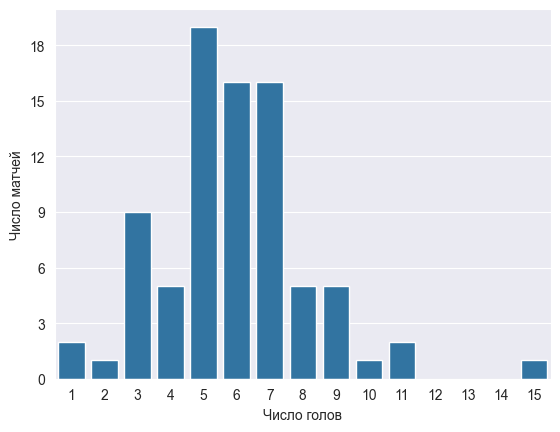

['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)', 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']
['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']


In [18]:
sns.countplot(x=games['Total Score'], order=range(games['Total Score'].min(), games['Total Score'].max() + 1))
plt.xlabel('Число голов')
plt.ylabel('Число матчей')
plt.yticks(range(0, 19, 3))
plt.show()

min_total = games['Total Score'].min()
max_total = games['Total Score'].max()

least_games = []
for game_id in games[games['Total Score'] == min_total].index:
    least_games.append(gameInfo(game_id))

most_games = []
for game_id in games[games['Total Score'] == max_total].index:
    most_games.append(gameInfo(game_id))

print(least_games)
print(most_games)

In [ ]:
#чаще всего в матче забивают 5 шайб, на 6 и 7 шайбах по 16 матчей. основная масса матчей приходится на 5–7 голов. Матчей с 1–2 шайбами совсем мало. Правее 11 шайб столбцов нет, затем стоит выброс на 15 шайбах. Столбцы на 12, 13, 14 пустые, потому что матчей с таким числом шайб не было. Распределение почти симметрично вокруг 5–7 с длинным правым хвостом. Параметр order показывает и значения без матчей (12–14), поэтому на оси нет «дыры». Сумма высот всех столбцов равна 82 (число игр), то есть ни одна игра не потерялась.

In [ ]:
# Самых нерезультативных игр две, в обеих забита всего одна шайба и обе закончились в овертайме: Montréal–Tampa Bay 0:1 и Philadelphia–Pittsburgh 1:0. Раз гол один, а овертайм был, значит, основное время закончилось 0:0, и решающая шайба упала в овертайме. Самая результативная игра одна, Colorado – Minnesota 9:6, 15 шайб за основное время. Я беру минимум и максимум из Total Score и вывожу все игры с такими значениями. Поэтому для нерезультативных игр список из двух матчей ничья по числу шайб (по 1 шайбе в двух играх). В этих двух играх хозяева один раз проиграли (0:1) и один раз выиграли (1:0), то есть преимущества своей площадки в них нет.

In [ ]:
#7

In [19]:
player_columns = nhl.loc[:, "Away Team's Player on the Ice #1":"Home Team's Goalie"]

game_infos = []
player_counts = []
for game_id in games.index:
    game_players = player_columns[nhl['Game ID'] == game_id]
    player_names = game_players.stack().dropna().unique()
    game_infos.append(gameInfo(game_id))
    player_counts.append(len(player_names))

players = pd.DataFrame({'Game Info': game_infos, 'Player Count': player_counts}, index=games.index)

max_players = players['Player Count'].max()
print(players[players['Player Count'] == max_players])

                                                    Game Info  Player Count
Game ID                                                                    
2025030216  Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...            40


In [ ]:
#Больше всего игроков участвовало в одной игре: Montréal – Buffalo (счёт 3:8) с номером 2025030216, их было 40. Игра единственная с таким максимумом. Это матч с большим перевесом хозяев с 11 шайбами. Я считаю игроков по 14 колонкам, шесть игроков на льду и вратарь, отдельно для гостей и хозяев. Пустые значения не считаю игроками, поэтому у меня 40, а в примере 41. Это пустое значение (вратаря сняли с ворот), и в примере оно посчитано как «игрок». Игра с максимумом одна и та же в обоих вариантах.

In [ ]:
#8

In [20]:
def goalDistance(x, y, goal_x):
    if y < -3:
        return ((x - goal_x) ** 2 + (y + 3) ** 2) ** 0.5
    elif y <= 3:
        return abs(x - goal_x)
    else:
        return ((x - goal_x) ** 2 + (y - 3) ** 2) ** 0.5


shot_types = ['shot-on-goal', 'goal', 'missed-shot']
shots = nhl[nhl['Play Type'].isin(shot_types)]

shot_lengths = []
for index, shot in shots.iterrows():
    shot_by_home = shot['Team Making the Play'] == shot['Home Team']
    home_defends_left = shot["Home Team's Defending Side"] == 'left'
    if shot_by_home == home_defends_left:
        goal_x = 89
    else:
        goal_x = -89
    shot_lengths.append(goalDistance(shot['X Coordinate on the Ice Rink'], shot['Y Coordinate on the Ice Rink'], goal_x))

nhl['Shot Length'] = pd.Series(shot_lengths, index=shots.index)

print(nhl[nhl['Play Type'].isin(shot_types)][['Game ID', 'Play Type', 'Shot Length']])


          Game ID     Play Type  Shot Length
7      2025030111   missed-shot       12.207
9      2025030111   missed-shot       12.000
12     2025030111   missed-shot       29.411
13     2025030111  shot-on-goal       62.169
19     2025030111   missed-shot       52.924
...           ...           ...          ...
29695  2025030416   missed-shot       54.083
29696  2025030416   missed-shot        5.099
29704  2025030416          goal       46.239
29706  2025030416   missed-shot       60.926
29707  2025030416  shot-on-goal       49.041

[7266 rows x 3 columns]


In [ ]:
#9

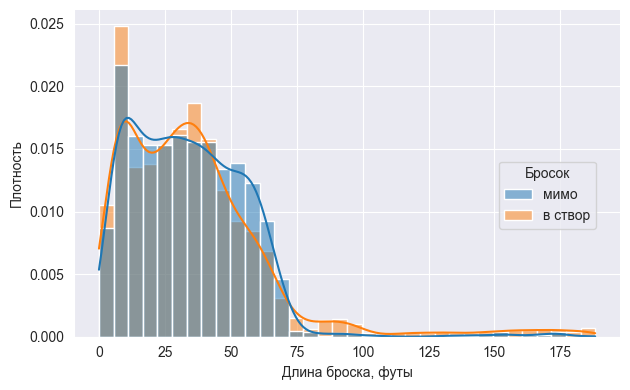

Бросок
в створ    4623
мимо       2643
Name: count, dtype: int64


In [29]:
shots = nhl[nhl['Shot Length'].notna()].copy()
shots['Бросок'] = 'в створ'
shots.loc[shots['Play Type'] == 'missed-shot', 'Бросок'] = 'мимо'

g = sns.displot(data=shots, x='Shot Length', hue='Бросок', hue_order=['мимо', 'в створ'], stat='density', common_norm=False, kde=True, bins=34, height=4, aspect=1.6, facet_kws={'legend_out': False})
g.set_axis_labels('Длина броска, футы', 'Плотность')
sns.move_legend(g, 'center right', bbox_to_anchor=(0.95, 0.5))
plt.show()

print(shots['Бросок'].value_counts())

In [ ]:
# Распределения длины точных и неточных бросков похожи: почти все броски сделаны с расстояния до 75 футов, у обеих групп два пика, около 10 и около 35 футов. Значит, дальность броска почти не влияет на то, попадёт ли шайба в створ. Вблизи ворот (около 10 футов) выше столбцы у точных бросков, а в диапазоне 40–65 футов чуть выше у неточных. Главное отличие справа: у неточных бросков распределение обрывается после 75–100 футов, а у точных тянется хвостом до 185 футов. Этот длинный хвост это скорее всего броски в пустые ворота, когда проигрывающая команда снимает вратаря, и дальние броски плохо, которые долетели до ворот и были отбиты вратарём. Дальние броски мимо видимо не фиксируют как броски, поэтому у неточных хвоста нет.

In [ ]:
#10

In [21]:
unblocked = nhl[nhl['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot'])].copy()
unblocked['On Goal'] = unblocked['Play Type'] != 'missed-shot'

numshots = unblocked.groupby(['Game ID', 'Team Making the Play'])[['On Goal']].mean()
numshots.columns = ['Share of Shots on Goal']

print(numshots)
print(numshots['Share of Shots on Goal'].describe())

                                 Share of Shots on Goal
Game ID    Team Making the Play                        
2025030111 Boston Bruins                          0.625
           Buffalo Sabres                         0.679
2025030112 Boston Bruins                          0.614
           Buffalo Sabres                         0.636
2025030113 Boston Bruins                          0.694
...                                                 ...
2025030414 Vegas Golden Knights                   0.583
2025030415 Carolina Hurricanes                    0.558
           Vegas Golden Knights                   0.510
2025030416 Carolina Hurricanes                    0.639
           Vegas Golden Knights                   0.595

[164 rows x 1 columns]
count   164.000
mean      0.639
std       0.085
min       0.353
25%       0.583
50%       0.639
75%       0.689
max       0.860
Name: Share of Shots on Goal, dtype: float64


In [ ]:
#В таблице 164 строки. по две команды в каждой из 82 игр. В среднем в створ летит около 64% незаблокированных бросков (среднее и медиана 0,639), то есть примерно six-seven броcков. В половине случаев доля лежит между 0,583 и 0,689, разброс небольшой. Совсем неточные игры (минимум 0,353) и очень точные (максимум 0,860) встречаются редко. Среднее равно медиане => значения распределены примерно симметрично. Вывод: у команд точность бросков примерно одинаковая и довольно стабильная, сильно выбиваются из общей картины лишь единичные игры. Незаблокированные броски это shot-on-goal, goal и missed-shot, заблокированные в расчёт не входит. Доля точных = (в створ + голы) / (в створ + голы + мимо), для каждой команды в каждой игре

In [ ]:
#11.

In [22]:
avgnumshots = numshots.groupby('Team Making the Play')['Share of Shots on Goal'].mean()

print(avgnumshots.nlargest(5))
print(avgnumshots.nsmallest(5))

Team Making the Play
Edmonton Oilers       0.706
Philadelphia Flyers   0.684
Dallas Stars          0.670
Minnesota Wild        0.656
Colorado Avalanche    0.653
Name: Share of Shots on Goal, dtype: float64
Team Making the Play
Pittsburgh Penguins   0.554
Utah Mammoth          0.599
Carolina Hurricanes   0.615
Tampa Bay Lightning   0.626
Buffalo Sabres        0.626
Name: Share of Shots on Goal, dtype: float64


In [ ]:
# Самые точные бросающие команды: Edmonton (0,706), Philadelphia (0,684) и Dallas (0,670). Самая неточная команда Pittsburgh (0,554). Между ними разница около 15 пунктов (0,706 против 0,554). В нижней пятёрке Utah (0,599) заметно ниже, а Tampa Bay и Buffalo делят пятое-четвёртое место с одинаковыми 0,626. Это среднее из долей по играм, а не общая доля за весь плей-офф. каждая игра весит одинаково, независимо от числа бросков. Все пять лучших команд выше среднего по всем играм из пункта 10 (0,639), а все пять худших ниже. Команды отличаются сильно меньше, чем отдельные игры, средние по командам лежат между 0,554 и 0,706, а доли в отдельных играх бывали от 0,353 до 0,860.

In [ ]:
#12

In [23]:
unblocked['Is Goal'] = unblocked['Play Type'] == 'goal'

pergame = unblocked.groupby(['Game ID', 'Team Making the Play'])[['On Goal', 'Is Goal']].sum()
avgshots = pergame.groupby('Team Making the Play').mean()
avgshots.columns = ['Shot', 'Goal']

print(avgshots)

                       Shot  Goal
Team Making the Play             
Anaheim Ducks        31.667 3.250
Boston Bruins        25.167 2.000
Buffalo Sabres       30.462 3.308
Carolina Hurricanes  31.632 3.474
Colorado Avalanche   32.154 3.385
Dallas Stars         31.000 2.500
Edmonton Oilers      28.333 3.500
Los Angeles Kings    25.250 1.250
Minnesota Wild       28.727 3.727
Montréal Canadiens   23.263 2.842
Ottawa Senators      27.500 1.250
Philadelphia Flyers  24.600 2.100
Pittsburgh Penguins  26.500 1.833
Tampa Bay Lightning  28.000 2.143
Utah Mammoth         27.833 3.000
Vegas Golden Knights 26.545 3.455


In [ ]:
#Команды бросают в створ в среднем от 23 до 32 раз за игру. меньше всех Montréal (23,263), больше всех Colorado (32,154). По голам разница сильнее от 1,250 (Los Angeles и Ottawa) до 3,727 (Minnesota), то есть лучшая команда забивает примерно в 3 раза больше худшей. Dallas бросает 31,000 раз, но забивает только 2,500, а Vegas бросает 26,545 раз и забивает 3,455. При этом у Carolina, Colorado и Anaheim много бросков и много голов, так что какая-то связь между бросанием и попаданием есть, но не строгая.


In [ ]:
#13)

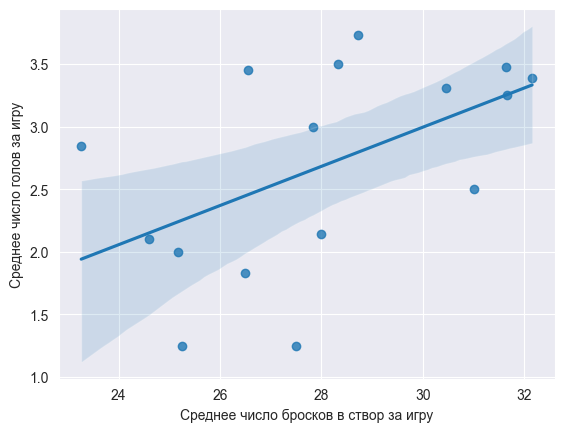

0.5207961205304794


In [24]:
sns.regplot(data=avgshots, x='Shot', y='Goal')
plt.xlabel('Среднее число бросков в створ за игру')
plt.ylabel('Среднее число голов за игру')
plt.show()

print(avgshots['Shot'].corr(avgshots['Goal']))

In [ ]:
#Линия регрессии идёт вверх => чем больше команда в среднем бросает в створ, тем больше голов она забивает. Корреляция 0,52 говорит об умеренной связи, что она есть, но не сильная. Точки сильно разбросаны вокруг линии, что команда с 26,5 броска забивает почти 3,5 гола, а две команды с 25–27,5 броска забивают всего около 1,25. Голубая полоса вокруг линии широкая, то есть при 16 командах линия определена неточно. То есть связь видна, но число бросков объясняет число голов лишь отчасти. Каждая точка это одна команда (16 точек). Линия показывает общую тенденцию, а голубая полоса вокруг неё это область, где линия могла бы лежать при другой выборке команд. Примерно четверть различий между командами по числу голов объясняется числом бросков, остальное чем-то другим. Эта связь описывает команды в среднем и не доказывает, что больше бросков вызывает больше голов

In [ ]:
#14)

In [25]:
all_shots = nhl[nhl['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot', 'blocked-shot'])]

shots_per_game = all_shots.groupby('Game ID').size()
idxmax = shots_per_game.idxmax()

print(shots_per_game.max())
print(gameInfo(idxmax))

208
Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)


In [ ]:
#Больше всего ударов по воротам было в матче Carolina – Ottawa: 208 ударов. Игра закончилась со счётом 3:2 и шла два овертайма => большое число ударов

In [ ]:
#15

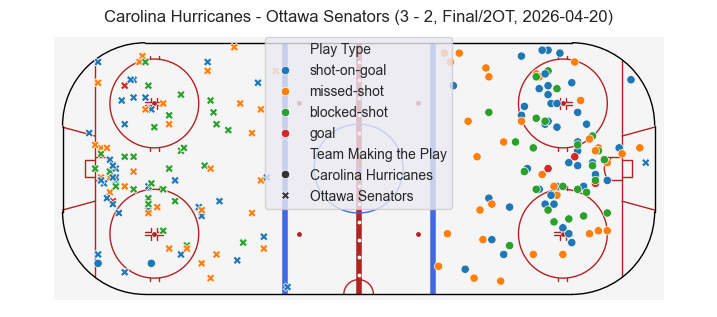

In [26]:
from rink import plot_rink
game_shots = all_shots[all_shots['Game ID'] == idxmax].copy()

odd_periods = game_shots['Period'] % 2 == 1
game_shots['X'] = game_shots['X Coordinate on the Ice Rink']
game_shots['Y'] = game_shots['Y Coordinate on the Ice Rink']
game_shots.loc[odd_periods, 'X'] = -game_shots.loc[odd_periods, 'X']
game_shots.loc[odd_periods, 'Y'] = -game_shots.loc[odd_periods, 'Y']

plt.figure(figsize=(7, 3))
plot_rink()
sns.scatterplot(data=game_shots, x='X', y='Y', hue='Play Type', style='Team Making the Play')
plt.axis('equal')
plt.axis('off')
plt.title(gameInfo(idxmax))
plt.tight_layout(pad=0.1)
plt.show()

In [ ]:
Точки собираются у ворот, слева это удары Ottawa (крестики), справа удары Carolina (кружки). В центре площадки точек мало. Почти все удары делаются недалеко от ворот соперника, а не издалека. Красных точек (голы) совсем немного, большинство ударов это синие (бросок в створ), оранжевые (мимо) и зелёные (заблокированные). Обе команды били с похожих мест и примерно в равном количестве

In [ ]:
#16

In [28]:
goals = nhl[nhl['Play Type'] == 'goal']

top_score = goals['Player in the Event #1'].value_counts()

print(top_score.head(10))
print(top_score[top_score == 7])

Player in the Event #1
Brett Howden        14
Pavel Dorofeyev     12
Logan Stankoven     11
Mitch Marner        10
Jordan Staal         8
Nikolaj Ehlers       8
Nathan MacKinnon     7
Taylor Hall          7
Mark Stone           7
Jackson Blake        7
Name: count, dtype: int64
Player in the Event #1
Nathan MacKinnon    7
Taylor Hall         7
Mark Stone          7
Jackson Blake       7
Alex Newhook        7
Matt Boldy          7
Name: count, dtype: int64


In [ ]:
#Лучший по голам в плей-офф Brett Howden (14 голов), потом Pavel Dorofeyev (12) и Logan Stankoven (11), Mitch Marner забил 10. Дальше у Nikolaj Ehlers и Jordan Staal по 8, а остальные в списке по 7. На десятое место претендуют сразу шесть игроков с 7 голами

In [ ]:
#17

In [29]:
assists = pd.concat([goals['Player in the Event #2'], goals['Player in the Event #3']])

top_assistants = assists.value_counts()

print(top_assistants.head(10))

Jack Eichel        20
Mitch Marner       19
Jackson Blake      13
Lane Hutson        13
Taylor Hall        12
Martin Necas       12
Nick Suzuki        12
Shea Theodore      12
Quinn Hughes       11
Kirill Kaprizov    11
Name: count, dtype: int64


In [ ]:
#Больше всего у Jack Eichel (20) и Mitch Marner (19), у третьего места только 13. Дальше с 11–13 передачами много кто. Mitch Marner есть и в списке лучших по голам из пункта 16 (10 голов), он и забивает, и отдаёт много передач. Jackson Blake и Taylor Hall тоже попали в оба списка (по 7 голов и 13 и 12 передач). Остальные в этом списке в десятке забивающих не встречаются

In [ ]:
#18

In [40]:
points = top_score.add(top_assistants, fill_value=0).astype(int)
points = points.sort_values(ascending=False)

print(points.head(10))
print(points[points == 16])

Mitch Marner       29
Jack Eichel        22
Jackson Blake      20
Taylor Hall        19
Shea Theodore      18
Nikolaj Ehlers     18
Brett Howden       18
Nick Suzuki        16
Lane Hutson        16
Pavel Dorofeyev    16
Name: count, dtype: int64
Nick Suzuki        16
Lane Hutson        16
Pavel Dorofeyev    16
Logan Stankoven    16
Name: count, dtype: int64


In [ ]:
#Лидер Mitch Marner с 29 очками, потом Jack Eichel (22), Jackson Blake (20) и Taylor Hall (19). У троих по 18, у остальных по 16. Marner набрал почти на треть больше, чем второй, и это видно по прошлым пунктам, у него 10 голов и 19 передач. Brett Howden с 14 голами был лучшим бомбардиром, но по сумме с гол+пас он только пятый, то есть передач у него немного

In [ ]:
#19

In [32]:
on_goal = nhl[nhl['Play Type'].isin(['shot-on-goal', 'goal'])]
shots_total = on_goal['Player in the Event #1'].value_counts()

games_played = {}
for game_id in games.index:
    game_players = player_columns[nhl['Game ID'] == game_id].stack().dropna().unique()
    for player_name in game_players:
        games_played[player_name] = games_played.get(player_name, 0) + 1
games_played = pd.Series(games_played)

avg_shots = (shots_total / games_played).dropna().sort_values(ascending=False)

print(avg_shots.head(10))

Jason Robertson    5.000
Dylan Guenther     4.500
Nikita Kucherov    4.429
Matt Boldy         4.364
Quinton Byfield    4.250
Joel Eriksson Ek   4.000
Darren Raddysh     4.000
Alex Laferriere    3.750
David Pastrnak     3.667
Nathan MacKinnon   3.615
dtype: float64


In [ ]:
#Чаще всех в створ бросает Jason Robertson в среднем 5 бросков за игру, у Guenther 4,5, у Kucherov 4,429. Остальные из десятки лежат между 3,6 и 4,4. Ни одного игрока из десятки по очкам здесь нет => те, кто чаще всех бросает, не обязательно набирают больше всех очков.

In [ ]:
#20

In [33]:
hits = nhl[nhl['Play Type'] == 'hit']
hits_total = hits['Player in the Event #1'].value_counts()

avg_hits = (hits_total / games_played).dropna().sort_values(ascending=False)

print(avg_hits.head(10))
print(games_played[avg_hits.head(10).index])

Lawson Crouse        6.333
Alexander Petrovic   6.000
Alex Turcotte        6.000
Yakov Trenin         5.667
Dylan Cozens         5.500
Vasily Podkolzin     5.333
Marcus Foligno       5.000
Carl Grundstrom      5.000
Ivan Barbashev       5.000
Owen Tippett         4.833
dtype: float64
Lawson Crouse          6
Alexander Petrovic     1
Alex Turcotte          1
Yakov Trenin           9
Dylan Cozens           4
Vasily Podkolzin       6
Marcus Foligno        11
Carl Grundstrom        3
Ivan Barbashev        22
Owen Tippett           6
dtype: int64


In [ ]:
#Чаще всех силовые приёмы делает Lawson Crouse 6,3 за игру. Потом Alexander Petrovic и Alex Turcotte (по 6,0) и Yakov Trenin (5,7). У Crouse игр 6, у Trenin 9, у Podkolzin 6. Самый показательный результат у Ivan Barbashev: 5,0 приёма за игру, и он держит эту планку все 22 игры, больше всех в списке. Также стабильно выглядит Marcus Foligno (5,0 за 11 игр).

In [ ]:
#21)

In [34]:
home_goals = goals[goals['Team Making the Play'] == goals['Home Team']]
away_goals = goals[goals['Team Making the Play'] == goals['Away Team']]

conceded = set(zip(home_goals['Game ID'], home_goals["Away Team's Goalie"]))
conceded = conceded | set(zip(away_goals['Game ID'], away_goals["Home Team's Goalie"]))

played = set(zip(nhl['Game ID'], nhl["Away Team's Goalie"]))
played = played | set(zip(nhl['Game ID'], nhl["Home Team's Goalie"]))

clean_sheets = []
for game_id, goalie in played - conceded:
    if pd.notna(goalie):
        clean_sheets.append(goalie)

print(pd.Series(clean_sheets).value_counts())

Frederik Andersen     3
Dan Vladar            2
Brandon Bussi         2
Andrei Vasilevskiy    1
Scott Wedgewood       1
Jakub Dobes           1
Joonas Korpisalo      1
Arturs Silovs         1
Name: count, dtype: int64


In [31]:
# Всего восемь вратарей хотя бы раз не пропустили ни одного гола. У Frederik Andersen три игры без пропущенных. Dan Vladar и Brandon Bussi сделали это по два раза, остальные пятеро по одному разу. Число рядом с фамилией это количество игр, где вратарь не пропустил ни одного гола, пока был на льду. Все числа вместе дают 12 игр

In [ ]:
#22. В каком периоде забивают больше всего?

        Goals  Games  Goals per Game
Period                              
1         145     82           1.768
2         150     82           1.829
3         169     82           2.061
4          18     22           0.818
5           4      4           1.000


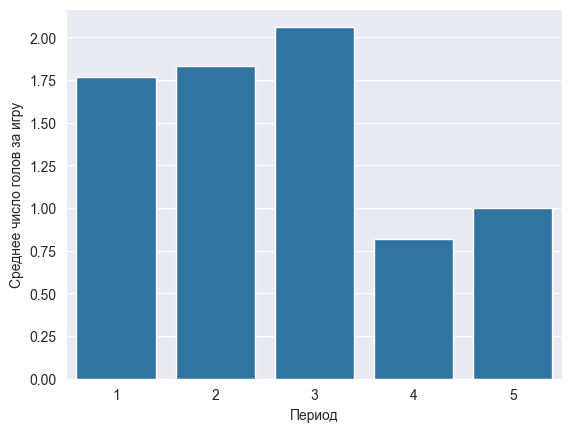

In [37]:
goals = nhl[nhl['Play Type'] == 'goal']

period_stats = pd.DataFrame({'Goals': goals['Period'].value_counts(), 'Games': nhl.groupby('Period')['Game ID'].nunique()})
period_stats = period_stats.sort_index()
period_stats['Goals per Game'] = period_stats['Goals'] / period_stats['Games']

print(period_stats)

sns.barplot(x=period_stats.index, y=period_stats['Goals per Game'])
plt.xlabel('Период')
plt.ylabel('Среднее число голов за игру')
plt.show()

In [30]:
#Вопрос выбран потому, что у матча есть разные части, и можно проверить, одинаково ли в них забивают. Голы делятся на число игр, в которых этот период был, потому что периоды 4 и 5 играются не во всех матчах
# Больше всего голов забивают в третьем периоде в среднем 2,061 гола за игру. В первом периоде 1,768, во втором 1,829, то есть с каждым периодом голов становится немного больше. Разница небольшая (около 0,3 гола за игру между первым и третьим периодом), но на графике она видна. Четвёртый и пятый периоды это овертаймы, четвёртый был в 22 играх из 82 (18 голов), пятый всего в 4 играх (4 гола). То есть из 22 игр с овертаймом 18 закончились голом уже в четвёртом периоде, а остальные 4 перешли в пятый и закончились там. Среднее за овертайм (0,818 и 1,000) нельзя сравнивать с основными периодами т. к. игр там мало (22 и 4), и овертаймы по определению заканчиваются при первом голе.

In [ ]:
#Общий вывод: В плей-офф 2025/2026 в среднем забивали около 6 шайб за матч, чаще всего 5–7. Около 64% бросков (кроме заблокированных) попадают в створ, и этот показатель у команд примерно одинаковый. Связь между числом бросков в створ и числом голов умеренная (корреляция 0,52): много бросков помогает, но не гарантирует много голов. Игроки с лучшими результатами по голам, передачам и очкам в основном разные, но Marner, Blake и Hall есть и в списках по голам, и по передачам. Результативность растёт от первого периода к третьему.